# 07. Isaac Sim + cuRobo MPPI 실습 — 카메라 없이 A→B 회피 돌려 보기

**목표**
- `hand_experiment.py`의 핵심 루프(SimulationApp → World/Franka → MpcSolver → `world.step` / `mpc.step` / `apply_action`)를 짧은 독립 스크립트로 직접 돌려 본다.
- 환경 충돌 비용의 activation distance η를 바꾸면 회피 경로·이격·도달 시간이 어떻게 달라지는지 내 손으로 확인한다.

**노션과의 연결**
- U1(MPC 루프: 매 step 재계획, 첫 행동만 실행), U3(η 비용식, 충돌 구 + buffer), U6(실행·추종: physics dt vs MPC dt, 측정 상태 입력).

**이 실습의 범위 (레포와 다른 점)**

| 항목 | franka-depth-mppi 대표 실험 | 이 실습 `scripts/mpc_lab.py` |
|---|---|---|
| 장애물 | D435i 깊이 → nvblox ESDF + 손 ROI 패치 | cuboid 1개 (손 ROI 위치 근처) |
| 충돌 checker | `BLOX` | `PRIMITIVE` (OBB만) |
| η 적용 대상 | 손 패치 전용 추가 비용에만 (환경 η는 25 mm 고정) | **테이블·벽·장애물 전체** 환경 비용 |
| 상태 입력 | measured q/v | measured q/v |
| 목표 | A→B, 실제 EE 도달(10 mm / 0.05 rad) 시 전환 | 동일 |

마지막 행이 중요하다. 여기서 η를 키우면 손 하나가 아니라 **모든 장애물**의 비용이 함께 커진다. 그래서 결과를 레포의 LOW/HIGH와 같은 실험으로 보면 안 된다.

In [1]:
from common import *
import subprocess, os
plt = setup_plot()

STUDY = Path.cwd()
LAB = STUDY / 'scripts' / 'mpc_lab.py'
RESULTS = STUDY / 'scripts' / 'results'
ISAAC = HOME / 'isaacsim'
check_paths()
print('LAB     ', 'OK ' if LAB.exists() else '없음', LAB)
print('RESULTS ', sorted(p.name for p in RESULTS.glob('*.jsonl')) if RESULTS.exists() else '없음')

REPO      OK  ~/franka-depth-mppi
CUROBO    OK  ~/curobo
TAPE      OK  ~/franka-depth-mppi/data/hand-tape-20261012-000004-472steps-registered
EVIDENCE  OK  ~/franka-depth-mppi/evidence
LAB      OK  ~/isaacsim/study_franka_mppi/scripts/mpc_lab.py
RESULTS  ['eta0.025.jsonl', 'eta0.07.jsonl', 'no_obstacle.jsonl']


## 1. Isaac Sim standalone 스크립트의 실행 구조

```text
python.sh mpc_lab.py
  │
  ├─ SimulationApp({...})          ← Kit 런타임 시작. omni.* / isaacsim.core.* import는 반드시 이 뒤
  ├─ World(physics_dt=1/60)        ← PhysX 장면
  ├─ add_robot_to_scene(franka)    ← URDF → USD, articulation + 관절 PD 드라이브
  ├─ MpcSolver(...)                ← cuRobo: rollout, 비용, MPPI optimizer (GPU 텐서 할당)
  │
  └─ for step:                     (1 step = physics 1/60 s)
       world.step()                ← 물리 1 step 진행 (직전 위치 명령을 PD 드라이브가 추종)
       measured = robot.get_joints_state()
       result = mpc.step(measured) ← MPPI 5 iter (첫 호출 때 CUDA graph capture)
       controller.apply_action(result.js_action.position)
```

**왜 SimulationApp을 먼저 만드나?** `isaacsim.core.api`, `omni.*`, `pxr` 같은 모듈은 Kit 확장 시스템이 올라온 뒤에야 import 경로가 잡힌다. 그래서 순서는 항상 `argparse → SimulationApp → 나머지 import`이다. `hand_experiment.py`도 63번째 줄에서 앱을 만든 다음 64번째 줄부터 Isaac 모듈을 import한다.

**시간 기준 세 가지**

| 이름 | 값 | 의미 |
|---|---|---|
| physics dt | 1/60 s | `world.step()` 한 번에 진행되는 물리 시간 |
| MPC model base dt (`step_dt`) | 1/60 s (이 실습, 레포 재생과 동일) | rollout 앞 15 step의 dt. 뒤 15 step은 0.04 s까지 선형 증가 |
| horizon 길이 | 0.675 s | `dt_array(1/60)` 합. 노션의 0.75 s는 base dt 0.02 기준 |

**관절 PD 추종:** `apply_action`은 위치 목표만 보낸다(velocity target 없음). 실제 관절은 PhysX 드라이브(stiffness·damping)가 따라간다. 그래서 MPC가 계획한 상태와 측정 상태가 다를 수 있고, 매 step 측정값을 다시 넣는 이유가 여기에 있다.

In [2]:
def show_section(path, start_marker, end_marker=None, width=130):
    """'# 1.' 같은 섹션 표시 줄부터 다음 표시 줄 직전까지 출력."""
    lines = Path(path).read_text().splitlines()
    s = next(i for i, l in enumerate(lines) if l.startswith(start_marker))
    e = next((i for i, l in enumerate(lines) if end_marker and l.startswith(end_marker)), len(lines))
    show_code(path, s + 1, e, width)

show_section(LAB, '# 1.', '# 2.')

   11| # 1. 인자 파싱 -> SimulationApp 생성 (omni/isaacsim 모듈은 반드시 이 뒤에 import)
   12| # ---------------------------------------------------------------------------
   13| import argparse
   14| import json
   15| import os
   16| import sys
   17| import tempfile
   18| import time
   19| from pathlib import Path
   20| 
   21| import numpy as np
   22| import torch
   23| 
   24| parser = argparse.ArgumentParser()
   25| parser.add_argument('--headless', action='store_true')
   26| parser.add_argument('--steps', type=int, default=600, help='physics steps (1/60 s each)')
   27| parser.add_argument('--eta', type=float, default=None, help='environment collision activation distance [m]; default 0.025 from par ...
   28| parser.add_argument('--buffer', type=float, default=0.02, help='collision_sphere_buffer [m] (hand_experiment uses 0.02)')
   29| parser.add_argument('--particles', type=int, default=None, help='MPPI num_particles (default 400)')
   30| parser.add_argument('--beta', type=float, 

**읽을 점**
- `--eta`, `--buffer`, `--particles`, `--beta`가 이 실습의 실험 손잡이다.
- `helper.add_robot_to_scene`은 `~/curobo/examples/isaac_sim/helper.py`에서 가져온다. 로컬 helper는 `(robot, path, view)` 세 값을 돌려주므로 `[0]`만 쓴다.
- 기본 장애물은 중심 (0.50, 0, 0.40), 크기 12×6×16 cm다. `target.json`의 손 ROI(x 0.42–0.58, z 0.32–0.48)와 겹치도록 골랐다.

In [3]:
show_section(LAB, '# 2.', '# 4.')

   72| # 2. Isaac Sim 장면: 지면, Franka, 목표 표시, 장애물 표시
   73| # ---------------------------------------------------------------------------
   74| ta = TensorDeviceType()
   75| world = World(stage_units_in_meters=1.0)
   76| world.set_simulation_dt(physics_dt=PHYSICS_DT, rendering_dt=PHYSICS_DT)
   77| stage = world.stage
   78| stage.SetDefaultPrim(stage.DefinePrim('/World', 'Xform'))
   79| world.scene.add_default_ground_plane()
   80| 
   81| robot_cfg = load_yaml(join_path(get_robot_configs_path(), 'franka.yml'))['robot_cfg']
   82| robot_cfg['kinematics']['collision_sphere_buffer'] = args.buffer
   83| robot = add_robot_to_scene(robot_cfg, world)[0]  # 로컬 helper 는 (robot, path, view) 를 반환
   84| joint_names = robot_cfg['kinematics']['cspace']['joint_names']
   85| q0 = robot_cfg['kinematics']['cspace']['retract_config']
   86| 
   87| for name, g in GOALS.items():
   88|     VisualCuboid(f'/World/goal_{name}', position=np.array(g[:3]), orientation=np.array(g[3:]),
   89|            

**장면과 충돌 세계는 별개다.**
- Isaac Sim 쪽 `VisualCuboid`는 **보이기만** 하는 객체다. 충돌도 물리도 없다.
- cuRobo가 실제로 피하는 장애물은 `WorldConfig(cuboid=[table, wall, obstacle])`이다. 시각 객체와 위치를 맞춰 둔 것뿐이다.
- 레포의 `hand_experiment.py`도 같은 구조다. 테이블·벽은 `collision_wall.yml`, 손은 nvblox 지도와 패치 cuboid이고, 화면의 복셀·패치 마커는 시각 표시일 뿐이다.
- cuRobo pose는 `[x, y, z, qw, qx, qy, qz]` 순서다(yml 주석의 `qx, qy, qz, qw`는 틀린 표기다).
- `PRIMITIVE` checker는 cuboid/OBB를 해석적으로 거리 계산한다. 레포의 `BLOX`는 nvblox ESDF를 조회한다(노트북 04 참고).

In [4]:
show_section(LAB, '# 4.', '# 5.')

  110| # 4. MPC solver (MPPI only). 모든 설정은 CUDA graph capture(첫 mpc.step) 전에 끝낸다.
  111| # ---------------------------------------------------------------------------
  112| override = {'mppi': {}}
  113| if args.particles is not None:
  114|     override['mppi']['num_particles'] = args.particles
  115| if args.beta is not None:
  116|     override['mppi']['beta'] = args.beta
  117| override_file = None
  118| if override['mppi']:
  119|     import yaml
  120|     override_file = os.path.join(tempfile.mkdtemp(), 'mppi_override.yml')
  121|     Path(override_file).write_text(yaml.safe_dump(override))
  122| 
  123| mpc_cfg = MpcSolverConfig.load_from_robot_config(
  124|     robot_cfg, world_cfg,
  125|     use_cuda_graph=True, use_cuda_graph_metrics=True, use_cuda_graph_full_step=False,
  126|     self_collision_check=True,
  127|     collision_checker_type=CollisionCheckerType.PRIMITIVE,
  128|     collision_cache={'obb': 10},
  129|     collision_activation_distance=args.eta,   # Non

**CUDA graph capture 전에 설정을 끝내는 이유**

`use_cuda_graph=True`이면 첫 `mpc.step()`에서 MPPI 반복 전체(샘플링 → rollout → 비용 → 가중치 → 평균·분산 갱신)를 CUDA graph로 녹화한다. 이후에는 같은 **메모리 주소**의 텐서로 graph를 재생할 뿐이다.

- 텐서 **값**을 in-place로 바꾸는 것(`fill_`, `copy_`)은 capture 뒤에도 반영된다. 목표 pose 갱신(`goal_buffer.goal_pose.copy_`)이 이렇게 동작한다.
- 텐서를 **새로 만들어 교체**하거나 크기·구조(입자 수, cost 함수 연결)를 바꾸면, 녹화된 graph는 옛 주소를 계속 쓴다. 변경이 반영되지 않거나 잘못된 메모리를 읽는다.

그래서
- 이 실습은 η·입자 수·β를 **solver 생성 시점의 config**(`collision_activation_distance`, `override_particle_file`)로 넣는다.
- 레포의 `TargetCostChannel`은 solver를 만든 뒤 capture 전에 `opt.rollout_fn.cost_fn`을 교체하고, `assert not opt.cu_opt_init`으로 순서를 확인한다. `--eta-exponent`도 `activation_distance.fill_(eta_p)`로 같은 텐서 주소의 값만 바꾸고 `data_ptr()`가 그대로인지 확인한다(`hand_experiment.py:104-111`).

In [5]:
show_code(REPO / 'experiment' / 'hand_experiment.py', 104, 111)
print()
# horizon 길이: common.dt_array 와 실행 기록 비교
for base in [0.02, 1 / 60]:
    print(f'base_dt={base:.4f}  horizon={dt_array(base).sum():.3f} s')
f = RESULTS / 'eta0.025.jsonl'
if f.exists():
    st = json.loads(f.read_text().splitlines()[0])
    print('실행 기록 horizon_s =', round(st['horizon_s'], 3), '| particles', st['num_particles'], '| n_iters', st['n_iters'],
          '| beta', st['beta'], '| eta', round(st['activation_distance_m'], 4), '| weight', st['collision_weight'])

  104| if args.eta_exponent is not None and args.condition!='R':
  105|  # Sensitivity override: same target-cost objects and alpha/weight; only the activation tensor value changes (in place, before CUDA graph capture).
  106|  import policy as _pol
  107|  hm=_pol.HAND_MASSES[POLICY_KEY];eta_p=_pol.REFERENCE_ETA_M*(_pol.reduced_mass(hm)/_pol.reduced_mass(_pol.REFERENCE_HAND_MASS_KG))**args.eta_exponent
  108|  for opt,c_,snap,old in channel.optimizers:
  109|   assert not opt.cu_opt_init;ptr=c_.activation_distance.data_ptr();c_.activation_distance.fill_(eta_p);assert c_.activation_distance.data_ptr()==ptr
  110|  channel.policy.update(eta_calculated_m=eta_p,eta_gpu_m=float(channel.optimizers[0][1].activation_distance[0]),eta_formula='0.025*(mu(m_h)/mu(0.6))**% ...
  111|  (session/'mass-policy.json').write_text(json.dumps(channel.policy,indent=2));print('ETA_OVERRIDE',json.dumps({'p':args.eta_exponent,'eta_m':eta_p,'gp ...

base_dt=0.0200  horizon=0.750 s
base_dt=0.0167  horizon=0.675

In [6]:
show_section(LAB, '# 5.')

  171| # 5. 제어 루프: physics step -> 측정 상태 -> mpc.step -> 위치 명령
  172| # ---------------------------------------------------------------------------
  173| world.reset()
  174| world.play()
  175| idx = [robot.get_dof_index(n) for n in joint_names]
  176| robot.set_joint_positions(q0, idx)
  177| robot._articulation_view.set_max_efforts(np.full(len(idx), 5000), joint_indices=idx)
  178| controller = robot.get_articulation_controller()
  179| cmd_idx = [robot.get_dof_index(n) for n in mpc.joint_names]
  180| 
  181| out = open(args.out, 'w') if args.out else None
  182| if out:
  183|     out.write(json.dumps({'type': 'settings', **settings}) + '\n')
  184| plan_i = 0
  185| events = [{'event': 'command', 'goal': PLAN[0], 'step': 0, 'sim_s': 0.0}]
  186| t0 = world.current_time
  187| 
  188| for step in range(1, args.steps + 1):
  189|     if not app.is_running():
  190|         break
  191|     world.step(render=not args.headless)
  192|     now = world.current_time - t0
  193| 
  194| 

**루프에서 볼 점**

1. **측정 상태 입력:** 위치와 속도를 Isaac에서 읽어 cuRobo 관절 순서로 정렬한다(`get_ordered_joint_state`). 레포 최종 실험의 `--state-input measured`와 같다. 노션 U1에 적어 둔 "직전 MPC 명령을 다음 입력으로 쓰는 방식"은 `--state-input command`이고, 대표 결과에는 쓰지 않았다.
2. **도달 판정은 실제 EE 기준:** `compute_kinematics(measured)`로 EE pose를 구하고, 10 mm·0.05 rad 이내가 되면 다음 목표로 바꾼다(`goal_progress.py`와 같은 규칙).
3. **`mpc.step(measured, max_attempts=2)`:** 내부에서 직전 해를 1 step shift해 warm start하고 MPPI를 5회 반복한다. `result.js_action`은 BEST 후보의 첫 명령 상태다.
4. **`feasible`:** 반환 명령 상태가 제약 검사를 통과했다는 뜻이다. 측정 상태가 장애물과 겹치지 않는다는 보장은 아니다(`docs/diagnosis.md` 마지막 문단).
5. **이격 계산:** 이 스크립트는 구 중심을 cuboid 좌표로 옮겨 해석적으로 계산한다. 레포의 `original_surface_clearance_m`(관측점 ↔ 구)와 정의가 다르다. 둘 다 반지름에 buffer를 포함하고, `clearance_bare_m = buffered + buffer`이다.

PD 드라이브 게인은 레포 실험 기록에 남아 있다.

In [7]:
cs = json.loads((EVIDENCE / 'HIGH' / 'control-settings.json').read_text())
print('drive stiffness', cs['drive_stiffness'][0], '| damping', cs['drive_damping'][0], '| kd/kp =', round(cs['drive_damping_over_stiffness_s'][0], 4), 's')
print('physics_dt', cs['physics_dt'], '| model_base_dt', cs['model_base_dt'], '| horizon', round(cs['trajectory_duration_s'], 3), 's')
print('filter', cs['filter_enabled'], cs['filter_coeff'], '| control_space', cs['control_space'])

drive stiffness 35809.86328125 | damping 572.9578247070312 | kd/kp = 0.016 s
physics_dt 0.016666666666666666 | model_base_dt 0.016666666666666666 | horizon 0.675 s
filter True {'position': 0.1, 'velocity': 0.1, 'acceleration': 0.0, 'jerk': 0.0} | control_space StateType.ACCELERATION


## 2. 실행

터미널에서 직접 실행할 때 (`~/isaacsim`에서):

```bash
PYTHONPATH=$HOME/curobo/src ./python.sh study_franka_mppi/scripts/mpc_lab.py --headless \
    --eta 0.025 --out study_franka_mppi/scripts/results/eta0.025.jsonl
# GUI로 보려면 --headless 를 빼면 된다
```

- 한 번 실행에 30–60초쯤 걸린다(앱 기동 + CUDA graph capture 포함). GPU 메모리는 8 GB 안에서 충분했다.
- Isaac Sim 프로세스가 이미 떠 있으면 GPU를 같이 쓰게 되니 먼저 끈다.
- 아래 셀은 같은 명령을 `subprocess`로 부른다. Isaac Sim을 띄우는 셀이라 자동 검증에서는 실행하지 않았다.

In [ ]:
def run_lab(name, *extra, steps=600, headless=True):
    """mpc_lab.py 를 별도 프로세스로 실행하고 results/<name>.jsonl 에 저장."""
    RESULTS.mkdir(parents=True, exist_ok=True)
    cmd = [str(ISAAC / 'python.sh'), str(LAB), '--steps', str(steps), '--out', str(RESULTS / f'{name}.jsonl'), *map(str, extra)]
    if headless:
        cmd.append('--headless')
    env = dict(os.environ, PYTHONPATH=str(CUROBO / 'src'))
    p = subprocess.run(cmd, cwd=ISAAC, env=env, capture_output=True, text=True)
    for line in p.stdout.splitlines():
        if line.startswith(('MPC_SETTINGS', 'ARRIVE', 'SUMMARY')):
            print(line[:300])
    print(name, 'exit', p.returncode)
    return p

run_lab('eta0.025', '--eta', 0.025)
run_lab('eta0.07', '--eta', 0.07)
run_lab('no_obstacle', '--no-obstacle')

## 3. 결과 비교

`results/`에 저장된 JSONL을 읽는다. 첫 줄은 설정, 마지막 줄은 요약, 나머지는 step별 기록이다.

In [8]:
def load_run(name):
    rows = read_jsonl(RESULTS / f'{name}.jsonl')
    steps = [r for r in rows if r['type'] == 'step']
    arrive = {e['goal']: e['sim_s'] for e in rows[-1]['events'] if e['event'] == 'arrive'}
    return dict(settings=rows[0], steps=steps, summary=rows[-1], arrive=arrive,
                t=np.array([r['sim_s'] for r in steps]),
                ee=np.array([r['ee_pos'] for r in steps]),
                err=np.array([r['pos_err_m'] for r in steps]),
                clr=np.array([np.nan if r['clearance_buffered_m'] is None else r['clearance_buffered_m'] for r in steps]),
                solver=np.array([r['solver_wall_s'] for r in steps]),
                feasible=np.array([r['feasible'] for r in steps]))

RUNS = {n: load_run(n) for n in ['no_obstacle', 'eta0.025', 'eta0.07'] if (RESULTS / f'{n}.jsonl').exists()}
if not RUNS:
    print('결과 파일이 없습니다. 위 실행 셀(run_lab)을 먼저 돌리세요.')
else:
    # far_s: B 지령 후 목표 오차가 0.6 m 이상인 시간 (장애물 앞 정체 정도)
    # clr_med: B 접근 중(오차 > 0.3 m) buffer 포함 이격의 중앙값
    print(f'{"run":12s} {"A 도달":>6s} {"B 도달":>6s} {"A→B":>5s} {"최소이격buf":>10s} {"bare":>7s} {"far_s":>6s} {"clr_med":>8s} {"feasible":>8s} {"solver":>7s}')
    for n, r in RUNS.items():
        buf = r['settings']['collision_sphere_buffer_m']
        has = np.isfinite(r['clr']).any()
        c = np.nanmin(r['clr']) if has else np.nan
        ab = r['arrive'].get('B', np.nan) - r['arrive'].get('A', np.nan)
        onB = np.array([s['goal'] == 'B' for s in r['steps']])
        dt = np.diff(r['t']).mean()
        far_s = (onB & (r['err'] >= 0.6)).sum() * dt
        clr_med = np.nanmedian(r['clr'][onB & (r['err'] > 0.3)]) if has else np.nan
        print(f'{n:12s} {r["arrive"].get("A", np.nan):6.2f} {r["arrive"].get("B", np.nan):6.2f} {ab:5.2f} '
              f'{c*1000:8.1f}mm {(c+buf)*1000:5.1f}mm {far_s:6.2f} {clr_med*1000:6.1f}mm {r["feasible"].mean():8.2f} {np.median(r["solver"])*1000:5.1f}ms')

run            A 도달   B 도달   A→B    최소이격buf    bare  far_s  clr_med feasible  solver
no_obstacle    2.17   5.05  2.88      nanmm   nanmm   0.45    nanmm     1.00   6.8ms
eta0.025       2.17   7.43  5.27    -21.3mm  -1.3mm   3.67   25.9mm     1.00   8.5ms
eta0.07        2.42   6.62  4.20     13.4mm  33.4mm   2.38   69.1mm     1.00   9.3ms


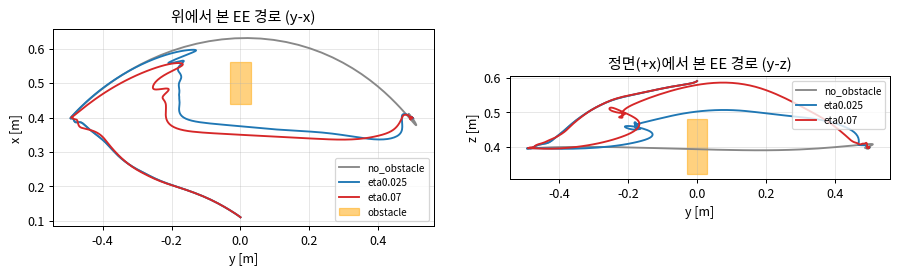

In [9]:
from matplotlib.patches import Rectangle
LC = {'no_obstacle': '#888888', 'eta0.025': '#1f77b4', 'eta0.07': '#d62728'}

if RUNS:
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    ob = next((r['settings']['obstacle'] for r in RUNS.values() if r['settings']['obstacle']), None)
    for n, r in RUNS.items():
        ax[0].plot(r['ee'][:, 1], r['ee'][:, 0], color=LC[n], label=n)
        ax[1].plot(r['ee'][:, 1], r['ee'][:, 2], color=LC[n], label=n)
    if ob:
        (x, y, z), (dx, dy, dz) = ob['pose'][:3], ob['dims']
        ax[0].add_patch(Rectangle((y - dy / 2, x - dx / 2), dy, dx, color='orange', alpha=0.5, label='obstacle'))
        ax[1].add_patch(Rectangle((y - dy / 2, z - dz / 2), dy, dz, color='orange', alpha=0.5))
    for a, yl, title, loc in [(ax[0], 'x [m]', '위에서 본 EE 경로 (y-x)', 'lower right'), (ax[1], 'z [m]', '정면(+x)에서 본 EE 경로 (y-z)', 'upper right')]:
        a.set_xlabel('y [m]'); a.set_ylabel(yl); a.set_title(title); a.set_aspect('equal'); a.legend(fontsize=8, loc=loc)
    plt.show()

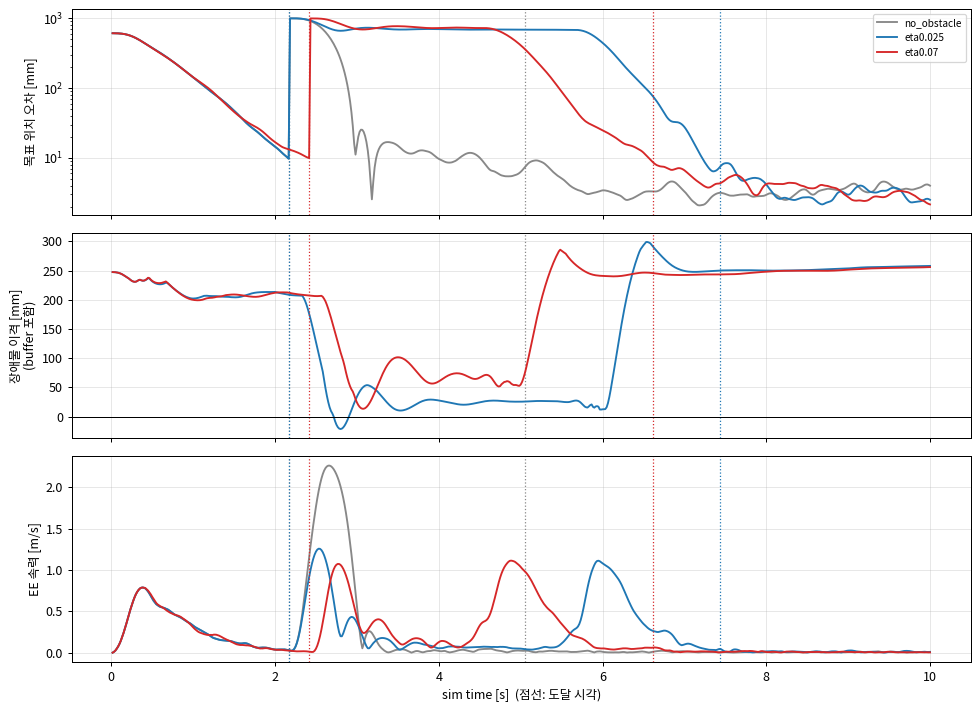

In [10]:
if RUNS:
    fig, ax = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
    for n, r in RUNS.items():
        ax[0].plot(r['t'], r['err'] * 1000, color=LC[n], label=n)
        ax[1].plot(r['t'], r['clr'] * 1000, color=LC[n], label=n)
        speed = np.r_[0, np.linalg.norm(np.diff(r['ee'], axis=0), axis=1) / np.diff(r['t'])]
        ax[2].plot(r['t'], speed, color=LC[n], label=n)
        for g, ts in r['arrive'].items():
            for a in ax:
                a.axvline(ts, color=LC[n], ls=':', lw=1)
    ax[0].set_ylabel('목표 위치 오차 [mm]'); ax[0].set_yscale('log')
    ax[1].set_ylabel('장애물 이격 [mm]\n(buffer 포함)'); ax[1].axhline(0, color='k', lw=0.8)
    ax[2].set_ylabel('EE 속력 [m/s]'); ax[2].set_xlabel('sim time [s]  (점선: 도달 시각)')
    ax[0].legend(fontsize=8)
    plt.tight_layout(); plt.show()

## 4. 해석 (2026-10-25 실행 기록 기준, seed 0, 조건별 1회)

| run | A 도달 | B 도달 | A→B | 최소 이격 (buffer 포함 / 제외) | 오차 ≥ 0.6 m 시간 | 접근 중 이격 중앙값 | EE 최고 z |
|---|---:|---:|---:|---:|---:|---:|---:|
| no_obstacle | 2.17 s | 5.05 s | 2.88 s | — | 0.45 s | — | 0.41 m |
| η = 25 mm | 2.17 s | 7.43 s | 5.27 s | −21.3 / −1.3 mm | 3.67 s | 25.9 mm | 0.51 m |
| η = 70 mm | 2.42 s | 6.62 s | 4.20 s | +13.4 / +33.4 mm | 2.38 s | 69.1 mm | 0.59 m |

1. **두 조건 모두 장애물 앞에서 정체했다.** 목표 오차가 0.7 m 근처에 머물고 EE가 천천히 움직이는 구간이 η = 25 mm에서 약 3.7 s, η = 70 mm에서 약 2.4 s였다. 노션 U1의 local minimum 그림과 같은 현상이다. 직진하면 충돌 비용이 커지고, 30 step(0.675 s) horizon 안에서는 크게 돌아가는 이득이 잘 드러나지 않는다.
2. **정체 중 이격이 η 근처에 머문다.** 접근 구간 이격 중앙값이 η = 25 mm에서 25.9 mm, η = 70 mm에서 69.1 mm였다. 비용은 간격 ≥ η에서 0이라, 목표 비용에 끌려 activation 경계까지 다가간 뒤 그 경계를 따라 미끄러지는 모양이다. **η가 "유지 거리"처럼 보이는 이유**지만 보장은 아니다. η = 25 mm에서도 빠져나가는 순간 buffer 포함 구가 21 mm 겹쳤다.
3. **η를 키웠더니 오히려 A→B가 1초 빨라졌다.** η = 70 mm는 더 높이(z 0.59 m) 우회했고 정체 구간이 짧았다. 노션 11.2절의 "활성 거리 증가가 항상 이동 시간 증가를 뜻하지 않는다"와 같은 방향이다. 다만 이 실습은 **환경 전체 η**를 바꿨기 때문에 출발→A 구간도 달라졌다(A 도달 2.17 → 2.42 s, 테이블·벽 비용도 같이 커짐). 정체가 왜 짧아졌는지는 후보 비용을 봐야 알 수 있고, 여기서는 확인하지 않았다.
4. **feasible은 모든 step에서 True였다.** buffer 포함 이격이 음수인 순간에도 그렇다. collision cost는 soft cost이고, feasible은 명령 상태 기준 검사라서 "측정 상태가 겹치지 않는다"와 같은 뜻이 아니다.
5. **조건별 단일 실행이다.** `fixed_samples=True`, seed 0이라 다시 돌려도 비슷하겠지만, 장애물 위치를 조금만 바꿔도 다른 우회 경로(위/옆)를 고를 수 있다. 일반화하려면 위치·seed를 바꿔 여러 번 돌려야 한다.

다시 실행하면 표의 숫자가 조금 달라질 수 있다. 위 코드 셀이 출력한 값을 기준으로 본다.

## 5. 해 볼 실험

| 실험 | 명령 인자 | 확인할 것 |
|---|---|---|
| η 스윕 | `--eta 0.01 / 0.025 / 0.05 / 0.07 / 0.1` | 최소 이격, A→B 시간, 머뭇거림 구간 길이가 단조롭게 변하나? |
| buffer | `--buffer 0.004` (cuRobo 기본) vs `0.02` | buffer 제외 이격이 어떻게 변하나? buffer와 η는 무엇이 다른가? |
| 입자 수 | `--particles 100 / 400 / 1000` | solver 시간, 경로의 매끄러움, local minimum 탈출 |
| β | `--beta 0.01 / 0.1 / 1.0` | weight 집중도 변화가 경로에 미치는 영향 (노트북 02의 toy와 비교) |
| 장애물 크기 | `--obstacle 0.5 0 0.4 0.12 0.2 0.3` | 우회 방향(위/옆)이 바뀌는 지점 |
| model dt | `--step-dt 0.02` | horizon 0.75 s vs 0.675 s, physics dt와 어긋날 때 추종 |

η를 손 비용에만 따로 주는 레포 구조를 따라 하려면, 노트북 05의 `TargetCostChannel`처럼 별도 `WorldPrimitiveCollision` + `PrimitiveCollisionCost`를 만들어 `cost_fn`에 더해야 한다. 이 실습을 확장해 보는 좋은 다음 과제다.

## 6. (참고) Jupyter 커널 안에서 SimulationApp을 직접 띄우려면

이 노트북은 Isaac Sim을 **별도 프로세스**(`subprocess` + `python.sh`)로 돌린다. 커널 안에서 직접 띄우는 것도 가능하지만 제약이 있다.

**방법:** Isaac Sim이 제공하는 `~/isaacsim/jupyter_notebook.sh`를 쓴다.
- Isaac 내장 파이썬(`kit/python/bin/python3`)에 `jupyter`를 pip로 설치하고, `jupyter_kernel/kernel.json`을 `isaac_sim_python3`("Isaac Sim Python 3") 커널로 등록한 뒤 노트북 서버를 띄운다. **Isaac 내장 파이썬에 패키지를 설치하는 단계라서** 실험 환경에 영향이 없는지 먼저 확인할 것.
- `setup_python_env.sh`로 잡은 환경 변수를 커널이 물려받는다. cuRobo를 쓰려면 서버를 띄우기 전에 `export PYTHONPATH=$HOME/curobo/src:$PYTHONPATH`를 해 두거나 셀에서 `sys.path`에 추가한다.

**주의점**
- **커널 하나에 SimulationApp은 한 번만** 만들 수 있다. `app.close()` 뒤 다시 만들 수 없으니 커널을 재시작해야 한다.
- 셀 실행이 끝나도 앱은 살아 있다. GUI를 갱신하려면 `world.step(render=True)`나 `app.update()`를 계속 불러야 한다. 루프가 길면 커널이 바빠 다른 셀을 못 돌린다.
- CUDA graph를 capture한 solver는 커널이 살아 있는 동안 GPU 메모리를 계속 잡는다.
- 그래서 반복 실험은 지금처럼 스크립트 + 결과 파일 방식이 다루기 쉽다.

아래는 Isaac 커널에서 쓸 때의 최소 형태다(자동 검증에서는 실행하지 않음).

In [ ]:
# "Isaac Sim Python 3" 커널에서만 실행. 커널당 한 번.
import sys
sys.path.insert(0, str(Path.home() / 'curobo' / 'src'))
from isaacsim import SimulationApp
app = SimulationApp({'headless': False, 'width': 1280, 'height': 720})

from isaacsim.core.api import World
world = World(stage_units_in_meters=1.0)
world.scene.add_default_ground_plane()
world.reset()
for _ in range(120):          # 2초 동안 화면 갱신
    world.step(render=True)
# ... 여기서 mpc_lab.py 의 2~5 블록을 셀 단위로 나눠 실행해 볼 수 있다.
# 끝나면 app.close()  → 이후 이 커널에서는 다시 SimulationApp 생성 불가

## 복습 질문

1. `SimulationApp`보다 `from isaacsim.core.api import World`를 먼저 쓰면 왜 실패하나?
2. CUDA graph capture 뒤 `activation_distance.fill_(0.07)`은 반영되는데 `cost.activation_distance = torch.tensor([0.07])`는 반영되지 않는 이유는?
3. 이 실습의 η 변경과 레포의 LOW→HIGH(손 패치 비용 η만 변경)는 무엇이 다르고, 그 차이가 A 도달 시각에서 어떻게 드러났나?
4. η = 25 mm 조건의 약 3.7초 정체를 노션 U1의 local minimum 설명으로 풀어 보라. horizon을 늘리면 어떻게 될까?
5. `feasible=True`인데 buffer 포함 이격이 −21 mm인 상황은 어떻게 가능한가?